# Full instrument: 30 analyser channels

Use the uninterrupted FANTASTIC elliptic guide and a 2–4 Å pulsed source.
Run from a fresh kernel, in cell order.


In [37]:
# CPU-compatible McStas build settings (also apply when rerunning this cell).
import os
import sys
from pathlib import Path
import tempfile

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

import mcstasscript as ms

# Each kernel builds on the local filesystem, away from shared .c/.out files.
workspace = Path.cwd().resolve()
build_directory = tempfile.TemporaryDirectory(prefix="full_instrument-", dir="/tmp")

instr = ms.McStas_instr(
    "full_instrument",
    author="McStasScript example",
    origin="Teaching example",
    input_path=build_directory.name,
    output_path=str(workspace / "full_instrument"),
    executable_path=str(Path(sys.prefix) / "bin"),
)


In [38]:
pulse_length = 400.0e-6
instr.add_parameter("pulse_length", value=pulse_length,
                    comment="Proton pulse duration for the moderator model [s]")
moderator_tau = 170.0e-6
instr.add_parameter("moderator_tau", value=moderator_tau,
                    comment="Cold moderator decay time used by Source_pulsed [s]")
moderator_n = 5.0
instr.add_parameter("moderator_n", value=moderator_n,
                    comment="Cold moderator pulse-shape parameter used by Source_pulsed")
moderator_time_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n
source_frequency = 50.0
instr.add_parameter("source_frequency", value=source_frequency,
                    comment="Source repetition rate [Hz]")
lambda_min = 2.0
instr.add_parameter("lambda_min", value=lambda_min,
                    comment="Minimum source wavelength [Angstrom]")
lambda_max = 4.0
instr.add_parameter("lambda_max", value=lambda_max,
                    comment="Maximum source wavelength [Angstrom]")


source_t_max = 0.004
instr.add_parameter("double", "source_t_max", value=source_t_max,
                    comment="End of Source_pulsed emission-time sampling window [s]")

# The uninterrupted elliptic guide
guide_parameters = {
    "linx": (0.611423, "Horizontal upstream focal distance [m]"),
    "liny": (1.04627, "Vertical upstream focal distance [m]"),
    "loutx": (1.68246, "Horizontal downstream focal distance [m]"),
    "louty": (1.94531, "Vertical downstream focal distance [m]"),
    "guide_length": (35.0, "Length of the uninterrupted elliptic guide [m]"),
    "guide_xwidth": (0.12, "Horizontal guide dimension at mid-length [m]"),
    "guide_yheight": (0.12, "Vertical guide dimension at mid-length [m]"),
    "d_source_guide": (0.5, "Source-to-guide entrance distance [m]"),
    "d_guide_sample": (1.5, "Guide exit-to-sample distance [m]"),
}
for name, (value, comment) in guide_parameters.items():
    instr.add_parameter("double", name, value=value, comment=comment)

instr.append_initialize('if (lambda_min <= 0 || lambda_max <= lambda_min || source_frequency <= 0 || pulse_length <= 0 || moderator_tau <= 0 || moderator_n <= 1 || source_t_max <= 0) { fprintf(stderr, "Invalid source parameters\\n"); exit(1); }')
instr.append_initialize('if (guide_length <= 0 || guide_xwidth <= 0 || guide_yheight <= 0 || d_source_guide <= 0 || d_guide_sample < 0 || linx <= 0 || liny <= 0 || loutx <= 0 || louty <= 0) { fprintf(stderr, "Invalid elliptic-guide geometry\\n"); exit(1); }')


In [39]:
source = instr.add_component("source", "Source_pulsed")
source.xwidth = 0.042
source.yheight = 0.03
source.Lmin = "lambda_min"
source.Lmax = "lambda_max"
source.t_min = 0.0
source.t_max = "source_t_max"
source.dist = "d_source_guide"
source.focus_xw = 0.04
source.focus_yh = 0.04
source.freq = "source_frequency"
source.t_pulse = "pulse_length"
source.T1 = 60.0
source.I1 = "1.75e12/source_frequency"
source.tau1 = "moderator_tau"
source.n_mod = "moderator_n"
source.I_um = "3.82e10/source_frequency"
source.tau_um = 12.0e-6
source.n_um = 5.0
source.chi_um = 0.9
source.kap_um = 2.2

guide = instr.add_component(
    "guide", "Elliptic_guide_gravity",
    AT=[0, 0, "d_source_guide"], RELATIVE="source"
)
guide.xwidth = "guide_xwidth"
guide.yheight = "guide_yheight"
guide.l = "guide_length"
guide.linxw = "linx"
guide.loutxw = "loutx"
guide.linyh = "liny"
guide.loutyh = "louty"
guide.dimensionsAt = '"mid"'
guide.option = '"ellipse"'
guide.R0 = 0.99
guide.Qc = 0.0218
guide.alpha = 6.07
guide.m = 4
guide.W = 0.003



In [40]:
guide_out = instr.add_component(
    "guide_out", "Arm", AT=[0, 0, "guide_length"], RELATIVE="guide"
)
sample_position = instr.add_component(
    "sample_position", "Arm",
    AT=[0, 0, "d_guide_sample"], RELATIVE="guide_out"
)


## Thirty analyser channels



In [41]:
channel_parameters = {
    "lambda_f": (4.0, "Analyser-selected wavelength [Angstrom]"),
    "channel_angle": (30.0, "Sample-to-analyser direction [degrees]"),
    "d_sample_analyser": (0.858, "Sample-to-analyser distance [m]"),
    "analyser_d": (3.357, "Analyser lattice spacing [Angstrom]"),
    "analyser_width": (0.07, "Total analyser width [m]"),
    "analyser_height": (0.03, "Total analyser height [m]"),
    "analyser_mosaic_h": (30.0, "Horizontal mosaic [arcmin]"),
    "analyser_mosaic_v": (30.0, "Vertical mosaic [arcmin]"),
    "analyser_NH": (11, "Horizontal blade count"),
    "analyser_NV": (11, "Vertical blade count"),
    "analyser_gap": (0.0005, "Blade gap [m]"),
    "analyser_detector_distance": (0.5, "FANTASTIC L2: separation along fixed detector arm [m]"),
    "detector_x": (2*0.75*0.0254, "Combined tube width [m]"),
    "detector_y": (22*0.0254, "Tube height [m]"),
    "sample_radius": (0.01, "Sample radius [m]"),
    "sample_height": (0.02, "Sample height [m]"),
    "sample_rotation_x": (0.0, "Sample x rotation [degrees]"),
    "sample_rotation_y": (0.0, "Sample y rotation [degrees]"),
    "sample_rotation_z": (0.0, "Sample z rotation [degrees]"),
}

channel_parameters["sample_E_tun"] = (2.5, "Tunneling energy transfer Ei - Ef [meV]")

channel_parameters["analyser_focusing"] = (1, "1: FANTASTIC focusing radii; 0: flat analyser")

for name, (value, description) in channel_parameters.items():
    parameter_type = "int" if name in ("analyser_NH", "analyser_NV") else "double"
    instr.add_parameter(parameter_type, name, value=value, comment=description)

In [42]:
for name in ("A5", "analyser_RH", "analyser_RV", "L_primary_channel", "tube_tmin", "tube_tmax"):
    instr.add_declare_var("double", name)
instr.add_declare_var("char", "tube_options", array=1024)
for name in ("detector_deflection", "detector_ray_path", "tube_center_y",
             "detector_hit_x", "detector_hit_y", "detector_hit_z"):
    instr.add_declare_var("double", name)
instr.append_initialize('if (lambda_f <= 0 || analyser_d <= 0 || lambda_f >= 2*analyser_d || d_sample_analyser <= 0 || analyser_detector_distance <= 0 || analyser_width <= 0 || analyser_height <= 0 || analyser_NH < 1 || analyser_NV < 1 || analyser_gap < 0 || analyser_mosaic_h <= 0 || analyser_mosaic_v <= 0 || detector_x <= 0 || detector_y <= 0 || sample_radius <= 0 || sample_height <= 0) { fprintf(stderr, "Invalid secondary-channel parameters\\n"); exit(1); }')
instr.append_initialize("A5 = asin(lambda_f/(2.0*analyser_d))*180.0/PI;")
# FANTASTIC L2 is the detector-arm separation; the ray path is L2/sin(2*A5).
instr.append_initialize("detector_deflection = 2.0*A5;")
instr.append_initialize('if (sin(DEG2RAD*detector_deflection) <= 1e-8) { fprintf(stderr, "Detector intersection is undefined at this Bragg angle\\n"); exit(1); }')
instr.append_initialize("detector_ray_path = analyser_detector_distance/sin(DEG2RAD*detector_deflection);")
instr.append_initialize("tube_center_y = -analyser_detector_distance/tan(DEG2RAD*detector_deflection);")
instr.append_initialize("detector_hit_x = (d_sample_analyser - tube_center_y)*sin(DEG2RAD*(offset + 60.0));")
instr.append_initialize("detector_hit_y = -analyser_detector_distance;")
instr.append_initialize("detector_hit_z = (d_sample_analyser - tube_center_y)*cos(DEG2RAD*(offset + 60.0));")
instr.append_initialize('printf("FANTASTIC fixed -90 deg detector arm: 2A5=%g deg; ray path=%g m; predicted ray local y=%g m (diagnostic only); ray intersection relative to sample=(%g,%g,%g) m\\n", detector_deflection, detector_ray_path, tube_center_y, detector_hit_x, detector_hit_y, detector_hit_z);')

instr.append_initialize('if (analyser_focusing != 0 && analyser_focusing != 1) { fprintf(stderr, "analyser_focusing must be 0 or 1\\n"); exit(1); }')
instr.append_initialize("analyser_RH = analyser_focusing ? -d_sample_analyser : 0.0;")
instr.append_initialize("analyser_RV = analyser_focusing ? -2.0*d_sample_analyser*sin(DEG2RAD*A5) : 0.0;")
instr.append_initialize("L_primary_channel = d_source_guide + guide_length + d_guide_sample;")
# Use the exact fixed acquisition interval from FANTASTIC_kyriakos_TUBES.
instr.append_initialize("tube_tmin = 0.02;")
instr.append_initialize("tube_tmax = 0.045;")
instr.append_initialize('snprintf(tube_options, sizeof(tube_options), "cylinder, y, bins=2, t, limits=[%.17g %.17g], bins=1000", tube_tmin, tube_tmax);')
instr.append_initialize('printf("30 analysers: lambda_f=%g A, A5=%g deg, RH=%g m, RV=%g m, detector interval=[%g,%g] ms\\n", lambda_f, A5, analyser_RH, analyser_RV, 1e3*tube_tmin, 1e3*tube_tmax);')


instr.append_initialize('if (source_t_max <= 0) { fprintf(stderr, "source_t_max must be positive\\n"); exit(1); }')

### Choose one sample model



### Sample angular sampling and the lead phonon model

For **Isotropic_Sqw**, `order=1` selects single scattering and `d_phi=3`
degrees restricts the vertical spreading of the Debye-Scherrer cone. The
horizontal scattering angles follow the input S(Q,w) and neutron
kinematics. This component has no target or focus-angle parameters.

Both **Tunneling_sample** and **Phonon_simple** aim at the middle of the
analyser arc using

$$\mathbf{u}=(\sin\phi,0,\cos\phi),\qquad
\phi=\mathrm{offset}+60^\circ.$$

Their `focus_aw=120` and `focus_ah=4` values are full horizontal and
vertical angular openings in degrees. For `Phonon_simple`, the sample
rotation is explicitly absolute, matching the component setup below. The
30 analyser centers remain at `offset + 0, 4, ..., 116` degrees.

`Phonon_simple` is a teaching approximation: an fcc Bravais lattice with
nearest-neighbour interactions, one acoustic phonon branch, and no phonon
polarization, Bragg scattering, incoherent scattering, or multiple
scattering. Its lead parameters should be treated as a simplified model,
not a full lead phonon-dispersion calculation.

In [43]:
USE_SQW = True  # Use the supplied S(Q,w) spectrum.
USE_PHONON_SIMPLE = False  # Select the simplified lead phonon model.

if USE_SQW and USE_PHONON_SIMPLE:
    raise ValueError("Select only one of USE_SQW and USE_PHONON_SIMPLE")

if not USE_SQW and not USE_PHONON_SIMPLE:
    instr.add_user_var("double", "sample_incident_energy")
    sample_position.append_EXTEND(
        "sample_incident_energy = VS2E*(vx*vx + vy*vy + vz*vz);"
    )
    instr.append_initialize(
        'if (sample_E_tun < 0) { fprintf(stderr, "sample_E_tun must be nonnegative\\n"); exit(1); }'
    )
    sample_tunneling = instr.add_component(
        "sample_tunneling", "Tunneling_sample",
        AT=[0, 0, 0], RELATIVE="sample_position"
    )
    sample_tunneling.radius = "sample_radius"
    sample_tunneling.yheight = "sample_height"
    sample_tunneling.thickness = 0.0
    sample_tunneling.p_interact = 1.0
    sample_tunneling.f_QE = 0.0
    sample_tunneling.f_tun = 1.0
    sample_tunneling.gamma = 0.0
    sample_tunneling.E_tun = "sample_E_tun"
    sample_tunneling.target_index = 0
    sample_tunneling.target_x = "sin((offset + 60) * M_PI / 180.0)"
    sample_tunneling.target_y = 0
    sample_tunneling.target_z = "cos((offset + 60) * M_PI / 180.0)"
    sample_tunneling.focus_aw = 120
    sample_tunneling.focus_ah = 4
    sample_tunneling.set_ROTATED(
        ["sample_rotation_x", "sample_rotation_y", "sample_rotation_z"],
        RELATIVE="sample_position"
    )
    sample_tunneling.append_EXTEND("""
if (!SCATTERED) { ABSORB; }
if (E_tun > 0) {
    double final_energy = VS2E*(vx*vx + vy*vy + vz*vz);
    if (final_energy >= sample_incident_energy) { ABSORB; }
    p *= 2.0;  /* Half the proposals have the requested energy-loss sign. */
}
""")

In [44]:
if USE_SQW:
    import shutil

    sqw_source = workspace / "SQW.dat"
    if not sqw_source.is_file():
        raise FileNotFoundError(f"Missing sample spectrum: {sqw_source}")
    sqw_input = Path(instr.input_path) / sqw_source.name
    shutil.copy2(sqw_source, sqw_input)
    print("S(Q,w) input copied to:", sqw_input)

    instr.add_parameter(
        "double", "sample_rho", value=0.05,
        comment="S(Q,w) scattering-unit number density [Angstrom^-3]"
    )
    instr.append_initialize(
        'if (sample_rho <= 0) { fprintf(stderr, "sample_rho must be positive\\n"); exit(1); }'
    )
    sample_sqw = instr.add_component(
        "sample_sqw", "Isotropic_Sqw",
        AT=[0, 0, 0], RELATIVE="sample_position"
    )
    sample_sqw.radius = "sample_radius"
    sample_sqw.yheight = "sample_height"
    sample_sqw.thickness = 0.0
    sample_sqw.rho = "sample_rho"
    sample_sqw.p_interact = 1.0
    sample_sqw.Sqw_coh = '"SQW.dat"'
    sample_sqw.order = 1
    sample_sqw.d_phi = 3

    sample_sqw.set_ROTATED(
        ["sample_rotation_x", "sample_rotation_y", "sample_rotation_z"],
        RELATIVE="sample_position"
    )
    sample_sqw.append_EXTEND("if (!SCATTERED) { ABSORB; }")

elif USE_PHONON_SIMPLE:
    sample_phonon = instr.add_component(
        "sample_phonon", "Phonon_simple",
        AT=[0, 0, 0], RELATIVE="sample_position"
    )
    sample_phonon.radius = 0.01
    sample_phonon.yheight = 0.01
    sample_phonon.sigma_abs = 0.171
    sample_phonon.sigma_inc = 0.003
    sample_phonon.a = 4.9396
    sample_phonon.b = 9.405
    sample_phonon.M = 207.2
    sample_phonon.c = 12.90095
    sample_phonon.DW = 1.0
    sample_phonon.T = 300.0
    sample_phonon.target_x = "sin((offset + 60) * M_PI / 180.0)"
    sample_phonon.target_y = 0.0
    sample_phonon.target_z = "cos((offset + 60) * M_PI / 180.0)"
    sample_phonon.focus_ah = 4.0
    sample_phonon.focus_aw = 120.0
    sample_phonon.set_ROTATED(
        ["sample_rotation_x", "sample_rotation_y", "sample_rotation_z"],
        RELATIVE="ABSOLUTE"
    )


S(Q,w) input copied to: /tmp/full_instrument-nlqv1o5g/SQW.dat


### Build the 30 analyser channels

Create all positioning arms first, followed by a contiguous analysers group. Their directions are offset + 4k, matching FANTASTIC; offset = 0 keeps the requested arc. Each analyser uses the matched FANTASTIC blade counts, mosaic, dimensions and focusing radii. GROUP lets a ray try the bank’s alternative analysers.


In [45]:
# FANTASTIC bank offset: zero retains the requested 0,4,...,116 degree arc.
instr.add_parameter("double", "offset", value=0.0,
                    comment="Rotation of the complete analyser bank [degrees]")

channel_angles = [4*k for k in range(30)]
for k, angle in enumerate(channel_angles):
    direction = f"offset + {angle}"
    arm = instr.add_component(
        f"ana_arm{k}", "Arm",
        AT=[f"d_sample_analyser*sin(DEG2RAD*({direction}))", 0,
            f"d_sample_analyser*cos(DEG2RAD*({direction}))"],
        RELATIVE="sample_position")
    arm.set_ROTATED([0, direction, 90], RELATIVE="sample_position")

for k in range(30):
    mono = instr.add_component(f"monochromator{k}", "Monochromator_curved",
                              AT=[0, 0, 0], RELATIVE=f"ana_arm{k}")
    mono.set_ROTATED([0, "-A5", 0], RELATIVE=f"ana_arm{k}")
    mono.width = "analyser_width"
    mono.height = "analyser_height"
    mono.gap = "analyser_gap"
    mono.NH = "analyser_NH"
    mono.NV = "analyser_NV"
    mono.mosaich = "analyser_mosaic_h"
    mono.mosaicv = "analyser_mosaic_v"
    mono.r0 = 0.99
    mono.t0 = 1.0
    mono.DM = "analyser_d"
    mono.RH = "analyser_RH"
    mono.RV = "analyser_RV"
    mono.order = 1
    mono.set_GROUP("analysers")


### Thirty slits and sixty tube monitors

The Slits and Detectors groups are each contiguous, as in the reference instrument. Each tube writes a unique filename, with two height bins, 1000 time bins, and the fixed FANTASTIC time limits.


In [46]:
for k in range(30):
    det_arm = instr.add_component(f"det_arm{k}", "Arm",
                                 AT=[0, 0, 0], RELATIVE=f"ana_arm{k}")
    det_arm.set_ROTATED([0, -90, 0], RELATIVE=f"ana_arm{k}")
for k in range(30):
    det_pos = instr.add_component(f"det_pos{k}", "Arm",
        AT=[0, 0, "analyser_detector_distance/2.0"], RELATIVE=f"det_arm{k}")
    det_pos.set_ROTATED([0, 0, 90], RELATIVE=f"det_arm{k}")
for k in range(30):
    slit = instr.add_component(f"collim{k}", "Slit",
                              AT=[0, 0, 0], RELATIVE=f"det_pos{k}")
    slit.xwidth = "detector_x/2.0"
    slit.yheight = "detector_y/2.0"
    slit.set_GROUP("Slits")
for tube_number, displacement in (
    (1, "-detector_x/4.0 - 0.0001"),
    (2, "detector_x/4.0 + 0.0001"),
):
    for k in range(30):
        tube = instr.add_component(f"tube{tube_number}_det{k}", "Monitor_nD",
            AT=[displacement, 0, "analyser_detector_distance/2.0"],
            RELATIVE=f"det_pos{k}")
        tube.set_ROTATED([0, 0, 0], RELATIVE=f"det_pos{k}")
        tube.xwidth = "detector_x/2.0"
        tube.yheight = "detector_y"
        tube.options = "tube_options"
        tube.filename = f'"tube{tube_number}_det{k}.dat"'
        tube.restore_neutron = 1
        tube.set_GROUP("Detectors")


Build directory: /tmp/full_instrument-nlqv1o5g
ASCII output base: /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/full_instrument/full_instrument
---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:3431386] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: tube1_det0_I=297.268 tube1_det0_ERR=60.1677 tube1_det0_N=1592 "tube1_det0.dat"
Detector: tube1_det1_I=387.098 tube1_det1_ERR=33.0994 tube1_det1_N=2050 "tube1_det1.dat"
Detector: tube1_det2_I=395.228 tube1_det2_ERR=23.9086 tube1_det2_N=2806 "tube1_det2.dat"
Detector: tube1_det3_I=407.42 tube1_det3_ERR=20.347 tube1_det3_N=3289 "tube1_det3.dat"
Detector: tube1_det4_I=368.669 tube1_det4_ERR=17.3843 tube1_det4_N=3763 "tube1_det4.dat"
Detector: tube1_det5_I=356.934 tube1_det5_ERR=15.2568 tube1_det5_N=4523 "tube1_det5.dat"
Detector: tube1_det6_I=377.611 tube1_det6_ERR=13.9883 tube1_det6_N=5341 "tube1_det6.dat"
Detector: tube1_det7_I=415.685 tube1_det7_ERR=13

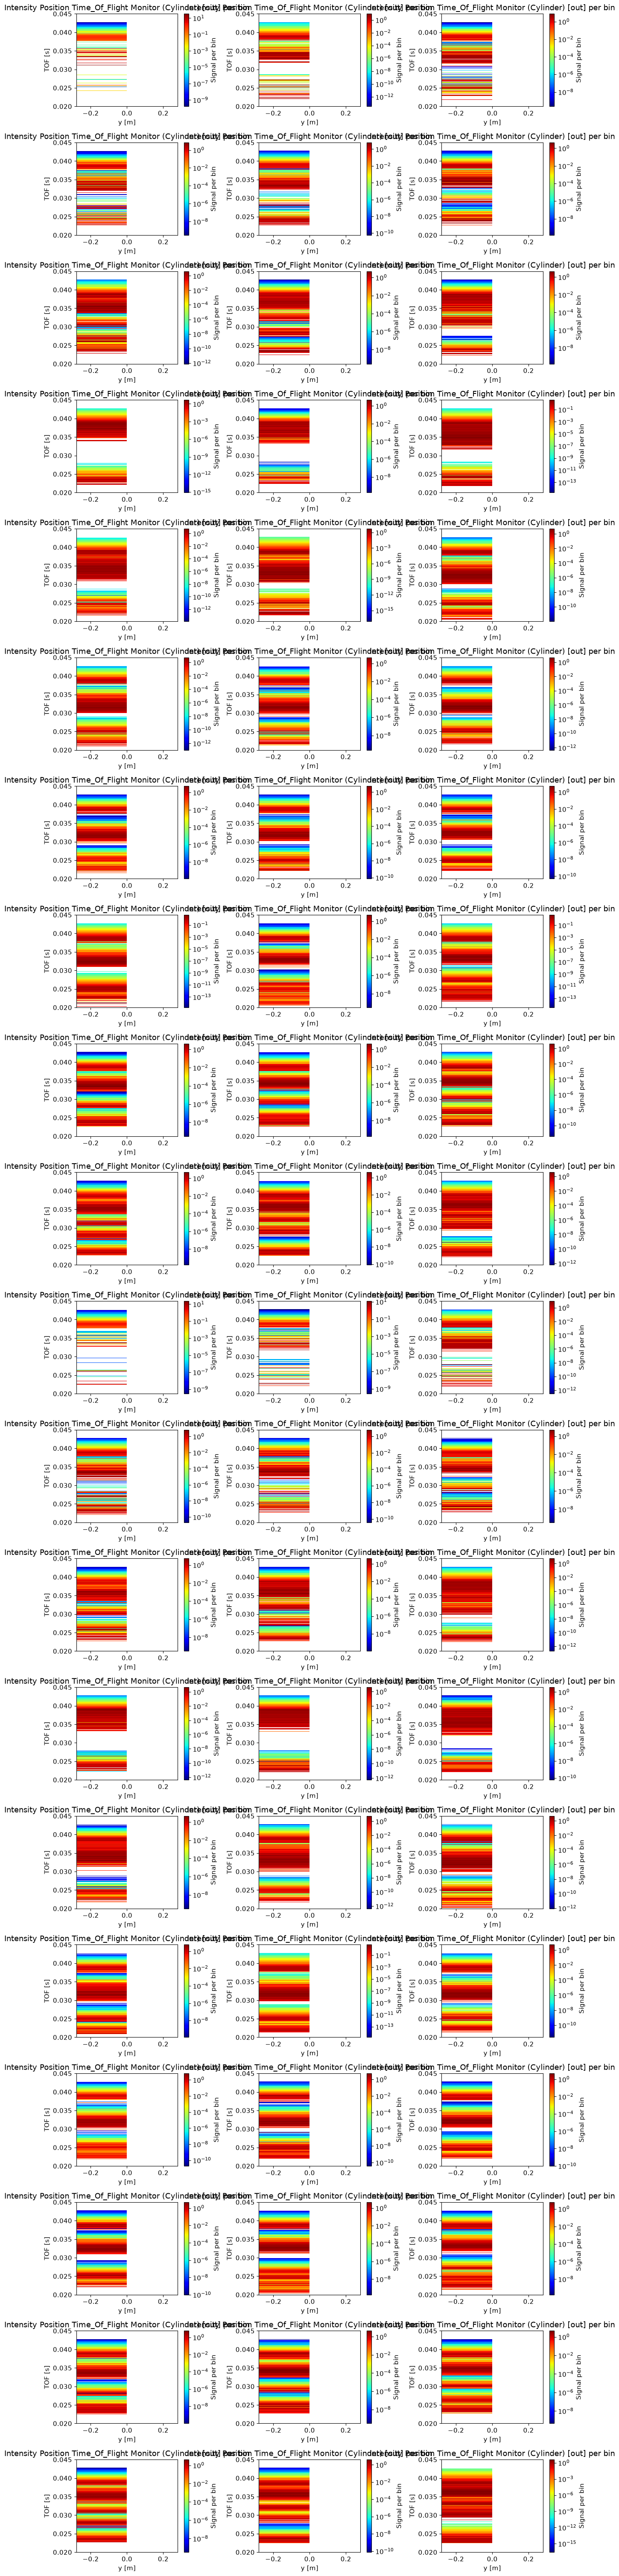

In [47]:
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

instr.settings(force_compile=True, ncount=1e10, mpi=12)

instr.write_full_instrument()
export_path = workspace / "full_instrument.instr"
export_temp = export_path.with_suffix(".instr.tmp")
export_temp.write_bytes((Path(instr.input_path) / "full_instrument.instr").read_bytes())
os.replace(export_temp, export_path)

print("Build directory:", instr.input_path)
print("ASCII output base:", instr.output_path)
data=instr.backengine()
ms.make_sub_plot(data,log=True)

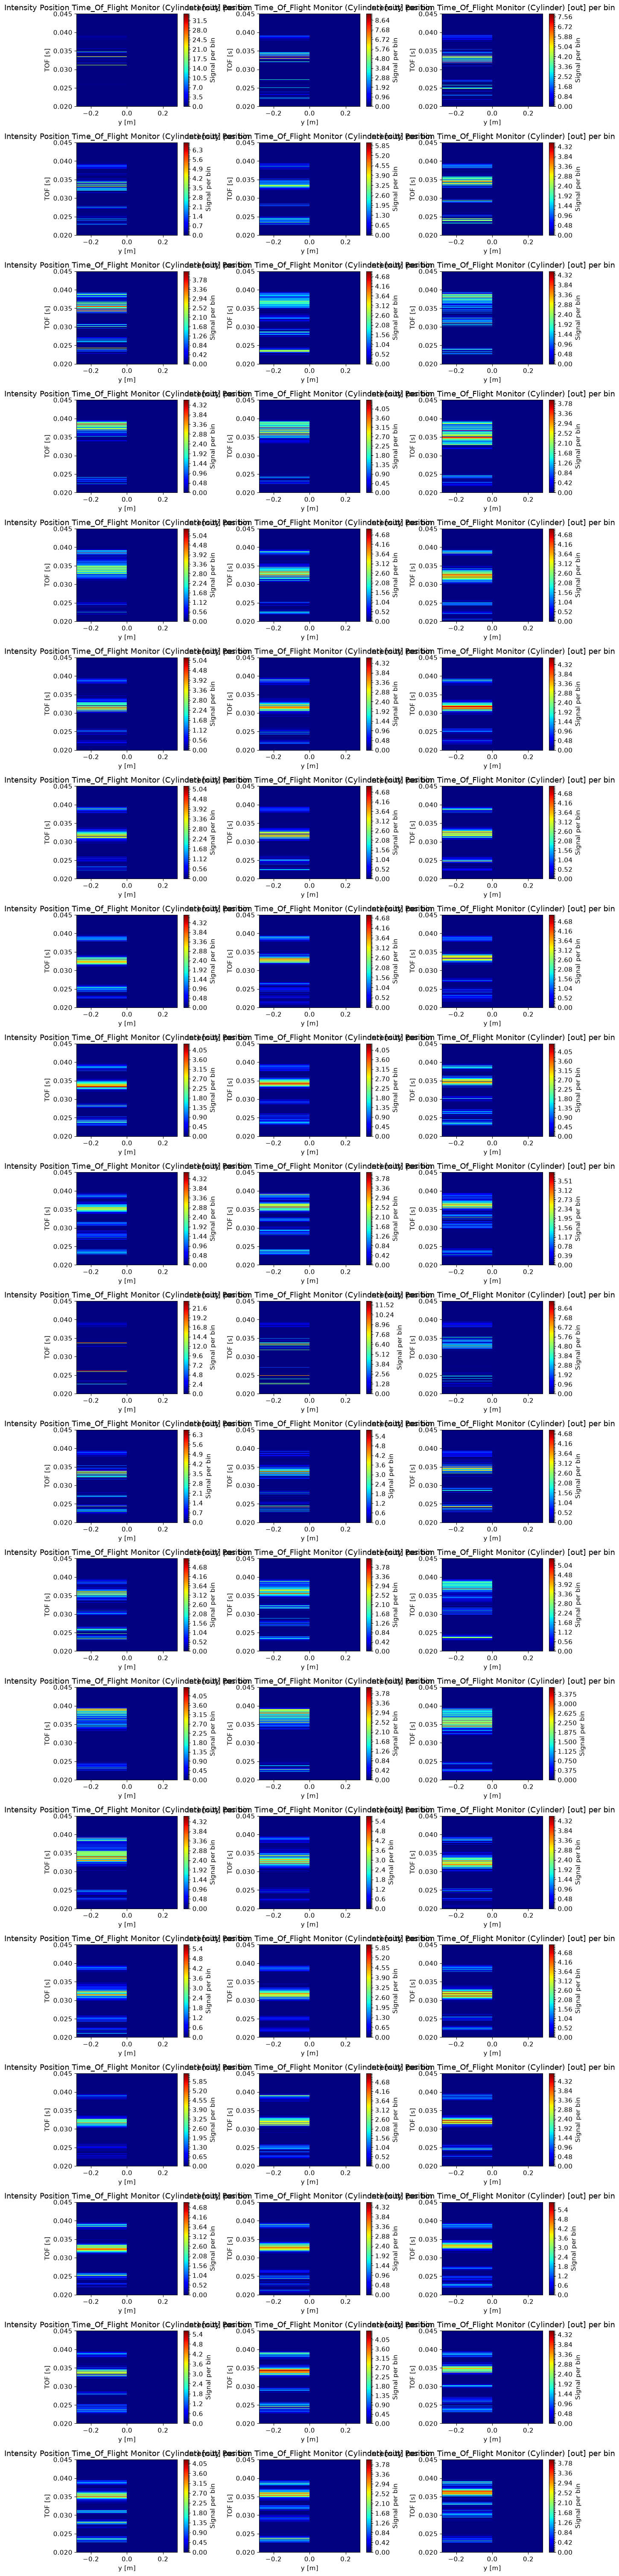

In [48]:
ms.make_sub_plot(data,log=False)